# VI.2 - Travaux pratiques

L'objectif de cette séance de travaux pratiques est de montrer l'utilisation des machines à vecteurs de support (*Support Vector Machines*, SVM) pour les problèmes de classification non-lineaire en python avec Scikit-learn.

Références externes utiles :

  * [Documentation NumPy](https://docs.scipy.org/doc/numpy/user/index.html)
  * [Documentation SciPy](https://docs.scipy.org/doc/scipy/reference/)
  * [Documentation MatPlotLib](http://matplotlib.org/)
  * [Site scikit-learn](http://scikit-learn.org/stable/index.html)
  * [Site langage python](https://www.python.org)
  * [Site LibSVM](https://www.csie.ntu.edu.tw/~cjlin/libsvm/)
  * [Site LibLinear](https://www.csie.ntu.edu.tw/~cjlin/liblinear/)

## Machines à vecteurs de support (SVM)

Les machines à vecteurs de support (SVM : *Support Vector Machines*) sont une classe des méthodes d'apprentissage statistique basées sur le principe de la maximisation de la marge (séparation des classes). Il existe plusieurs formulations (linéaires, versions à noyaux) qui peuvent s'appliquer sur des données séparables (linéairement) mais aussi sur des données non séparables.

Les avantages des SVM :

* Très efficaces en dimension élevée.
* Ils sont aussi efficaces dans le cas où la dimension de l'espace est plus grande que le nombre d'échantillons d'apprentissage.
* N'utilisent pas tous les échantillons d'apprentissage, mais seulement une partie (les vecteurs de support). En conséquence, ces algorithmes demandent moins de mémoire.

Désavantages :

* Si le nombre d'attributs est beaucoup plus grand que le nombre d'échantillons, les performances seront moins bonnes.
* Comme il s'agit de méthodes de discrimination entre les classes, elles ne fournissent pas directement des estimations de probabilités.

## Scikit-learn

Dans Scikit-learn, les SVM sont implémentées dans le module `sklearn.svm`. Dans cette partie nous allons nous intéresser à la version à noyaux (Scikit-learn utilise la bibliothèque LibSVM déjà discutée).

In [1]:
!pip install -U scikit-learn
# Une version récente de sklearn est nécessaire pour gamma='scale' (cf. plus bas)

    opencv-python (>=3.) ; extra == 'all'
                  ~~~~^


Relisez le TP SVM linéaire (partie Scikit-learn) pour vous remettre dans le contexte (quels sont les classes Python utilisées et leurs paramètres). La [documentation de scikit-learn sur les SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC) vous sera utile.

Nous allons reprendre la classification sur les données Iris.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split

# Chargement des données
iris = datasets.load_iris()
X, y = iris.data, iris.target
# On conserve 50% du jeu de données pour l'évaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

<div class="admonition-question admonition">

**Question**

Refaites la classification de la base de données `iris` mais avec un noyau gaussien. Testez l'effet du paramètre d'échelle du noyau (`gamma`) et du paramètre de régularisation `C`.

</div>

Comme dans le TP précédent, nous pouvons afficher la frontière de décision en ne conservant que deux variables explicatives :

In [3]:
X, y = iris.data[:,:2], iris.target
# On conserve 50% du jeu de données pour l'évaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

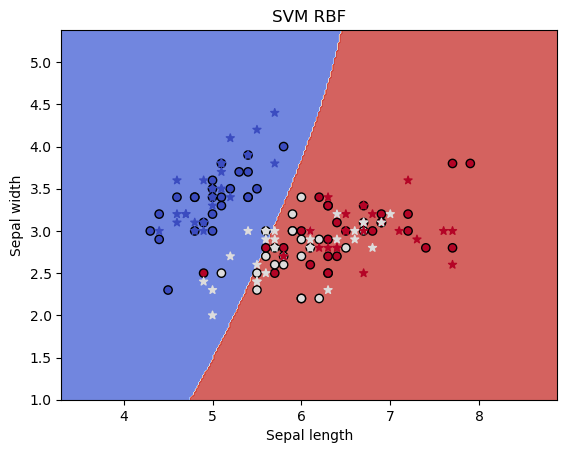

In [4]:
clf = svm.SVC(C=0.1, kernel='rbf', gamma=0.25)
clf.fit(X_train, y_train)

# Pour afficher la surface de décision on va discrétiser l'espace avec un pas h
h = .02
# Créer la surface de décision discretisée
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Surface de décision
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
# Afficher aussi les points d'apprentissage
plt.scatter(X_train[:, 0], X_train[:, 1], label="train", edgecolors='k', c=y_train, cmap=plt.cm.coolwarm)
plt.scatter(X_test[:, 0], X_test[:, 1], label="test", marker='*', c=y_test, cmap=plt.cm.coolwarm)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.title("SVM RBF")
plt.show()

<div class="admonition-question admonition">

**Question**

Que constatez-vous par rapport au TP précédent ?

</div>

## Jeu de données Digits

Reprenons notre base de données Digits de chiffres manuscrits.

(1797, 64)
(1797,)


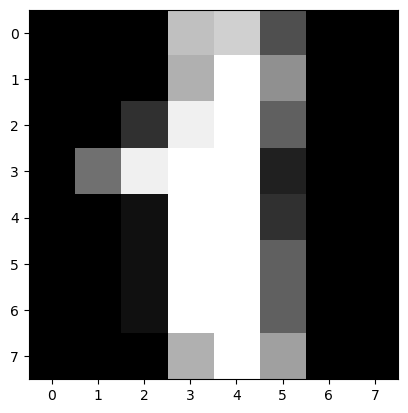

In [47]:
from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

digits = load_digits()
X, y = digits.data, digits.target
print(X.shape)
print(y.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)



<div class="admonition-question admonition">

**Question**

Réalisez une classification par une SVM linéaire et une SVM à noyau gaussien du jeu de données Digits. Comment est choisi le paramètre `gamma` dans scikit-learn ? Testez différentes valeurs de ce paramètre pour évaluer son influence. En particulier, testez les paramètres `gamma='auto'` et `gamma='scale'`. À quoi correspondent-ils ?

</div>

In [25]:
param_grid = {
    'gamma': [0.1, 0.3, 0.5, 0.7, 0.9, 'auto', 'scale']
}

grid_search = GridSearchCV(
    svm.SVC(C=0.1, kernel='rbf'),
    param_grid=param_grid
)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)


{'gamma': 'scale'}


<div class="admonition-question admonition">

**Question**

Réalisez une analyse en composante principale (ACP) et gardez les 2 premières composantes principales (voir la [documentation Scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)). Ensuite faites une classification avec un noyau gaussien et affichez les points de test ainsi que la surface de décision (reprendre le code du TP SVM linéaire). Comparez avec une SVM linéaire.

</div>

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
print("Dimensions :", X.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(X_pca.shape)


Dimensions : (1797, 64)
(1797, 2)


<div class="admonition-question admonition">

**Question**

Réalisez une recherche par grille afin de déterminer sur le jeu de données Digits complet (sans l'ACP) :

- le meilleur noyau à utiliser,
- la meilleure valeure de `C`,
- la meilleure valeur de `gamma` (ou le degré du polynome pour un noyau polynomial).
- (optionnel) la meilleure valeur de `n_components` de l'ACP

</div>

In [1]:
param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'C': [0.1, 0.3, 0.5, 0.7, 0.9]
}

grid_search = GridSearchCV(
    svm.SVC( gamma='scale'),
    param_grid=param_grid
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur score :", grid_search.best_score_)


NameError: name 'GridSearchCV' is not defined

<div class="admonition-question admonition">

**Question**

(optionnel) Combien de composantes faut-il garder au minimum dans l'ACP pour classer correctement au moins 97% des images ? À quel facteur de réduction de dimension cela correspond-il ?

</div>

In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

for i in range(1,15):
    pca = PCA(n_components=i)
    X_trainpca = pca.fit_transform(X_train)
    print(X_trainpca.shape)
    
    param_grid = {
        'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
        'C': [0.1, 0.3, 0.5, 0.7, 0.9]
    }
    
    grid_search = GridSearchCV(
        svm.SVC( gamma='scale'),
        param_grid=param_grid
    )
    
    grid_search.fit(X_trainpca, y_train)
    
    print("Meilleurs paramètres :", grid_search.best_params_)
    print("Meilleur score :", grid_search.best_score_)



(1437, 1)
Meilleurs paramètres : {'C': 0.7, 'kernel': 'rbf'}
Meilleur score : 0.4029544134727061
(1437, 2)
Meilleurs paramètres : {'C': 0.9, 'kernel': 'rbf'}
Meilleur score : 0.6715229384436702
(1437, 3)
Meilleurs paramètres : {'C': 0.9, 'kernel': 'rbf'}
Meilleur score : 0.7675740418118467
(1437, 4)
Meilleurs paramètres : {'C': 0.7, 'kernel': 'rbf'}
Meilleur score : 0.8761324041811847
(1437, 5)
Meilleurs paramètres : {'C': 0.9, 'kernel': 'rbf'}
Meilleur score : 0.9290093883081687
(1437, 6)
Meilleurs paramètres : {'C': 0.9, 'kernel': 'rbf'}
Meilleur score : 0.9443307200929152
(1437, 7)
Meilleurs paramètres : {'C': 0.9, 'kernel': 'rbf'}
Meilleur score : 0.9540819783197833
(1437, 8)
Meilleurs paramètres : {'C': 0.9, 'kernel': 'rbf'}
Meilleur score : 0.9645204219899343
(1437, 9)
Meilleurs paramètres : {'C': 0.7, 'kernel': 'rbf'}
Meilleur score : 0.979123112659698
(1437, 10)
Meilleurs paramètres : {'C': 0.7, 'kernel': 'rbf'}
Meilleur score : 0.9805144212156407
(1437, 11)
Meilleurs paramètre

## Approfondissement : LibSVM

<div class="admonition note">

**Note**

Cette partie est facultative. Elle vous permet de manipuler directement les bibiothèques LibLinear et LibSVM sur lesquelles s'appuie scikit-learn pour les machines à vecteur de supports. Ces implémentations sont très rapides et sont écrites en langage C.

Il est nécessaire d'avoir un compilateur C fonctionnel pour cette partie.

</div>

LibSVM est une implémentation sous licence libre qui s'est imposée ces derniers années et qui est utilisée par beaucoup de logiciels comme moteur de classification. Par exemple, Scikit-learn utilise cette bibliothèque pour son module `sklearn.svm`.

Pour l'obtenir et la compiler suivre ces pas :

In [ ]:
%%bash
cd ~
rm -rf tpsvm
mkdir tpsvm
cd tpsvm
wget http://cedric.cnam.fr/~ferecatu/RCP209/libsvm-3.22.tar.gz
tar xzvf libsvm-3.22.tar.gz
cd libsvm-3.22/
make

Pour comprendre les différents noyaux disponibles dans cette bibliothèque et leurs paramètres, lisez le document README dans le répertoire `libsvm-3.22/`.

Dans une première étape, nous allons essayer de dépasser les performances de `libLinear` sur la base de données MNIST en utilisant un C-SVC à noyau gaussien. Nous allons tester seulement 2 classes, les chiffres 5 et 6.

In [ ]:
%%bash
cd ~
cd tpsvm
# Récupérer et compiler libLinear
wget http://cedric.cnam.fr/~ferecatu/RCP209/liblinear-2.2.tar.gz
tar xzvf liblinear-2.2.tar.gz
cd liblinear-2.2/
make
# Récupérer la base de données
cd ~
cd tpsvm
mkdir databases
cd databases
wget http://cedric.cnam.fr/~ferecatu/RCP209/mnist.bz2
wget http://cedric.cnam.fr/~ferecatu/RCP209/mnist.t.bz2
bzip2 -d mnist.bz2
bzip2 -d mnist.t.bz2
cat mnist | grep '^5 \|^6 ' | shuf -n 2000 > 56
cat mnist.t | grep '^5 \|^6 ' | shuf -n 1000 > 56.t
# Nombre d'échantillons d'apprentissage de la classe 5
cat 56 | grep '^5' | wc -l
# >>> 951
# Nombre d'échantillons d'apprentissage de la classe 6
cat 56 | grep '^6' | wc -l
# >>> 1049

Entrainer un modèle C-SVM linéaire avec les paramètres par défaut :

In [ ]:
%%bash
../liblinear-2.2/train 56 56.model_linear
../liblinear-2.2/predict 56.t 56.model_linear 56.t.output_linear
# >>> Accuracy = 96.4% (964/1000)

Entrainer un modèle C-SVM à noyau gaussien et paramètres par défaut :

In [ ]:
%%bash
../libsvm-3.22/svm-train 56 56.model_default
../libsvm-3.22/svm-predict 56.t 56.model_default 56.output_default
# >>> Accuracy = 52.3% (523/1000) (classification)

Comme on peut le voir, les performances avec les paramètres par défaut ne sont pas très bonnes. Surtout le paramètre `gamma` est beaucoup trop petit (`gamma` est inversement proportionnel à la variance de la gaussienne, donc on est en situation de sous apprentissage - gaussienne trop large, car variance élevée). Par la suite on va mettre les données à l'échelle (chaque attribut entre 0 et 1) et garder toujours les paramètres par défaut.

In [ ]:
%%bash
../libsvm-3.22/svm-scale -l 0 56 > 56.scaled
../libsvm-3.22/svm-scale -l 0 56.t > 56.t.scaled
../liblinear-2.2/train 56.scaled 56.scaled.model_linear
../liblinear-2.2/predict 56.t.scaled 56.scaled.model_linear 56.t.scaled.output_linear
# >>> Accuracy = 96.7% (967/1000)
# On ne gagne pas beaucoup avec un classifieur linéaire
../libsvm-3.22/svm-train 56.scaled 56.scaled.model_default
../libsvm-3.22/svm-predict 56.t.scaled 56.scaled.model_default 56.scaled.output_default
# >>> Accuracy = 97.8% (978/1000) (classification)

<div class="admonition-question admonition">

**Question**

Cette fois-ci les résultats sont meilleurs. Regardez le fichier `56.scaled.model_default`, quelles sont les valeurs des paramètres C et `gamma` ?

</div>

Nous allons chercher les meilleurs paramètres par *grid search* pour ce jeux de données.

In [ ]:
%%bash
python ../libsvm-3.22/tools/grid.py -svmtrain ../libsvm-3.22/svm-train 56.scaled
# >>> [local] 5 -7 98.7 (best c=32.0, g=0.0078125, rate=98.7)
# >>> ...
# >>> 8.0 0.03125 99.15

Le script nous propose `C = 8` et `gamma = 0.03125`.

In [ ]:
%%bash
../libsvm-3.22/svm-train -c 8 -g 0.03125 56.scaled 56.scaled.model
../libsvm-3.22/svm-predict 56.t.scaled 56.scaled.model 56.scaled.output
# >>> Accuracy = 99.3% (993/1000) (classification)

<div class="admonition-question admonition">

**Question**

Un bien meilleur score donc que dans le cas linéaire.

Extraire un partie de 10000 échantillons de la base MNIST (toutes les 10 classes) et réduire le jeux de données entre 0 et 1. Coupez la base en deux parties égales apprentissage (`train`) et test (`test`) avec `libsvm-3.22/tools/subset.py`. Comparez le classifieurs libLinear et libSVM avec les paramètres par défaut. Esayez d'autres noyaux que le gaussien. Faites varier les parametres.

</div>

### SVM-toy

Par la suite on va explorer l'outil `svm-toy` qui permet de visualiser la classification pour des problèmes en deux dimensions.

In [ ]:
%%bash
cd ~/tpsvm/libsvm-3.22/svm-toy/gtk
make
./svm-toy

<div class="admonition-question admonition">

**Question**

Cliquez sur la surface d'affichage pour ajouter des points d'apprentissage. Changez de couleur pour ajouter une nouvelle classe (l'outil gère aussi la classification multi-classe). Utilisez l'option `-t 2` pour sélectionner la classification par noyau gaussien. Pour changer le paramètre C=valeur utilisez l'option `-c valeur` (par exemple : `-c 2.5`). Pour changer le paramètre `gamma` du noyau utilisez l'option `-g valeur` (par exemple : `-g 2.5`). Testez plusieurs valeurs pour les paramètres C et `gamma` afin de comprendre leur effet sur le fichier suivant : `04.dat`. Générez d'autres jeux de données par vous-même est testez d'autres noyaux (voir le fichier `libsvm-3.22/README`).

</div>

<div class="admonition-question admonition">

**Question**

*[Optionnel : à faire à la fin du TP si'il vous reste du temps]* Regardez les sources `c` de la bibliothèque libSVM. Où sont implementés les noyaux ? Ajoutez le noyau angulaire dans le code (K(x, y) = - ||x-y||) et recompilez svm-toy. Testez-le avec un jeu de données de type spirale (voir transparent 27 du cours). Comparez avec le noyau gaussien.

</div>